# 02 — Manifold · Raghavan et al. 2021 (PDAC)
Re-score the developmental modules canonically, test whether the developmental axis is a proliferation confound, then fit a **curve** (non-branching topology → `scFates.tl.curve`, not `tree`) directly on the existing UMAP (no re-embedding of a linear compartment). Derive the root from the signatures\u2019 developmental order (Gast/pSom origin; Crest is late), check the fitted curve for folds by its own edges, and confirm the stored orientation is pseudotime-consistent.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed data; score developmental modules (union control pool)
Graph-smooth the raw scores (kNN-connectivity averaging) for reading geography, keeping the raw per-cell means as the honest module readout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 7168 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.18
Gast: 73/81 genes present
pSom: 85/98 genes present
Crest: 103/104 genes present
raw module means (honest readout): {'Gast': -0.0076, 'pSom': 0.0711, 'Crest': -0.0216}


### Is the developmental axis a proliferation confound? (the Kürten/Lin cell-cycle fork)
The two lobes split by cell cycle. Test whether that split *is* the developmental axis: smoothed spatial module correlations, per-compartment module means, the Crest-high decile\u2019s compartment distribution, and each module\u2019s Spearman correlation with the cycling score. Modules are orthogonal to proliferation → keep the whole manifold (no scoping).

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile distribution across compartments:', frac)
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs cycling score: rho = {rho:+.2f}')
print('-> developmental axis is not defined by the proliferation split; keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.29
  Crest_sm vs Gast_sm: r = -0.79
  Crest_sm vs pSom_sm: r = -0.68

per-compartment smoothed developmental means:
             Gast_sm  pSom_sm  Crest_sm
compartment                            
Cycling      -0.0339   0.0683   -0.0094
Ductal-body  -0.0062   0.0711   -0.0227

Crest-high decile distribution across compartments: {'Ductal-body': 0.61, 'Cycling': 0.39}
  Gast vs cycling score: rho = -0.20
  pSom vs cycling score: rho = -0.04
  Crest vs cycling score: rho = +0.11
-> developmental axis is not defined by the proliferation split; keep whole manifold (no scoping).


### Fit the principal curve (non-branching) + fold diagnostic
Topology matched to the embedding: 2 tips / 0 forks across a Nodes sweep → a **curve**, not a tree. The fold diagnostic renders the fitted curve\u2019s own edges: the minimum Euclidean distance between graph-distant nodes, in units of the median edge length. Ratio > 1 ⇒ the curve does not fold back through the cloud.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nodes in [15, 20, 30]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(sub, Nodes=Nodes, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(sub)
    print(f'curve Nodes={Nodes}: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'committed curve (Nodes=20): {tips} tips, {forks} forks, self-approach {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve Nodes=15: 2 tips, 0 forks | fold self-approach ratio = 2.92
curve Nodes=20: 2 tips, 0 forks | fold self-approach ratio = 2.57
curve Nodes=30: 2 tips, 0 forks | fold self-approach ratio = 2.12
committed curve (Nodes=20): 2 tips, 0 forks, self-approach 2.57 (>1 = fold-free)


### Root from developmental order → pseudotime
For each tip, take the mean smoothed module scores of the cells nearest it and root at the tip that maximises Gast+pSom−Crest (the gastrulation/somitogenesis origin; neural crest is a **late** readout, never the root). Then check the module gradients along pseudotime.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=+0.0016 pSom=+0.0824 Crest=-0.0331
tip 2: Gast=-0.0101 pSom=+0.0596 Crest=-0.0180
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.435 p=0.0e+00
  pSom_sm: rho=-0.735 p=0.0e+00
  Crest_sm: rho=+0.608 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.59
Somitogenesis-high decile mean pseudotime = 0.06
Gastrulation-high decile mean pseudotime = 0.02


### Orientation consistency (independent of the embedding it tests)
The house orientation `X_umap_lin` was fixed in 01 from the variance axis; here it is *tested* against pseudotime — correlation of x-coordinate with pseudotime, and the angle between the variance axis and the pseudotime axis. A round overall cloud is fine as long as these agree.

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.88
variance-axis vs pseudotime-axis disagreement = 13.2deg (small -> equivalent orientation)


### Save `manifold.h5ad` + deliverable figure `manifold.pdf`
House (3.5, 1.5) strip on `X_umap_lin`, pseudotime colour with an external colourbar.

saved manifold.h5ad + manifold.pdf


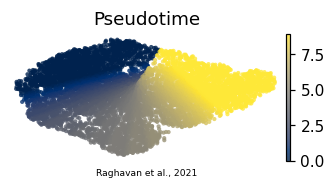

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')